# TP : First-Visit Monte Carlo sur les échecs — **8 stratégies, 4 combos, 3 agents hybrides à 2 modèles**

**Bibliothèques** : `python-chess`, `numpy`, `pandas`, `matplotlib`, `tqdm` (la partie *pygame/pymunk* du TP d'origine reste compatible : toute stratégie ci-dessous est une fonction `policy(board) -> move`, donc `ChessPhysicsSim.play_episode(ma_strategie)` fonctionne tel quel).

## Plan
0. Ce que le TP d'origine ne montre pas (3 problèmes + corrections)
1. Outils communs de l'environnement
2. **8 stratégies de base**
3. **4 combos** (mélange ε, changement de phase, cascade, vote)
4. **Cellule « 2 modèles »** : un modèle pour un cas, un autre pour un autre cas (3 agents hybrides)
5. Expériences : gauntlet vs aléatoire, round-robin, coût/force, **rapidité (nombre de coups)**, **justesse des coups (correct / imprécis / gaffe)**, ablation, méta-bandit, MC vs TD(0)
6. **Note de synthèse** : interprétations, comparaisons, limites, extensions

In [1]:
!pip install python-chess numpy pandas matplotlib tqdm
import chess, random, math, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict, Counter
from tqdm.auto import tqdm

SEED      = 42     # reproductibilité
MAX_PLIES = 120    # longueur max d'une partie (demi-coups)
ADJ       = 3      # écart de matériel pour "gagner" à l'arbitrage
random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("python-chess", chess.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 34.2 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for chess: filename=chess-1.11.2-py3-none-any.whl size=147878 sha256=da695b386d5b3e4b86ac55be45c8a2dcc6920c162020dc226622d243d12c2956
  Stored in directory: /root/.cache/pip/wheels/74/65/99/8c3a88ba852c1ed8d34daed144b8cb4c654d638677483d19ff
Successfully built chess
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [python-chess]
python-chess 1.11.2


## 0. Trois problèmes du TP d'origine (et nos corrections)

| # | Problème dans le code d'origine | Conséquence | Correction ici |
|---|---|---|---|
| 1 | `terminal_reward` renvoie `0.0` quand la partie **n'est pas finie** (limite `MAX_EPISODES = 200` demi-coups) | une partie tronquée = **défaite** des Blancs : le biais tire tous les `V` vers 0 | `result_score` : partie tronquée **arbitrée au matériel** (≥ +3 victoire, ≤ −3 défaite, sinon nulle) |
| 2 | Les 3 premiers épisodes (animés) ne mettent **jamais** `V` à jour | 3 épisodes perdus, code incohérent | l'animation est séparée de l'apprentissage ; ici tout épisode apprend |
| 3 | `V` est indexé par **FEN complet** | quasi aucun état n'est revu → la moyenne se fait sur 1 seul retour | **état abstrait** `(écart de matériel, phase, trait)` — voir §5.8 |

La cellule suivante mesure le problème n°3.

In [ ]:
# Combien de fois revoit-on un même état (FEN) en 300 parties aléatoires ?
def random_policy(board):
    return random.choice(list(board.legal_moves))

visits, seen = 0, Counter()
for _ in range(300):
    b = chess.Board()
    for _ in range(100):
        if b.is_game_over(): break
        seen[b.board_fen() + (" w" if b.turn else " b")] += 1; visits += 1
        b.push(random_policy(b))
repeated = sum(1 for k, c in seen.items() if c > 1)
print(f"visites totales      : {visits}")
print(f"états distincts      : {len(seen)}")
print(f"états vus > 1 fois   : {repeated}  ({100*repeated/len(seen):.2f} %)")

visites totales      : 29517
états distincts      : 28824
états vus > 1 fois   : 112  (0.39 %)


**Lecture.** Sur ~29 500 visites d'états en 300 parties aléatoires, seulement **0,39 %** des états distincts sont revus plus d'une fois. Avec γ = 1 et une récompense uniquement terminale, le « premier passage » d'un état FEN ne produit donc qu'**un seul** retour : `V(s)` = résultat de cette unique partie (0, 0,5 ou 1). Ce n'est pas une *moyenne*, donc pas une estimation Monte Carlo utile. C'est la limite annoncée dans les objectifs du TP (grands espaces d'états) : il faut **généraliser** (abstraction d'état, approximation de fonction).

## 1. Outils communs
Récompense du point de vue des Blancs, matériel (P=1, N=B=3, R=5, D=9), phases de jeu, détecteurs tactiques (capture, mat en 1) et moteur de partie `play_game` (avec `on_state` pour enregistrer les états visités).

In [ ]:
# ------------------------------------------------------------------
# Environnement : outils communs
# ------------------------------------------------------------------
PV  = {chess.PAWN: 1, chess.KNIGHT: 3, chess.BISHOP: 3, chess.ROOK: 5, chess.QUEEN: 9, chess.KING: 0}
ATT = {**PV, chess.KING: 100}          # valeur "attaquant" (le roi attaque en dernier)

def material(board):
    """Matériel du point de vue des Blancs (P=1, N=B=3, R=5, Q=9)."""
    s = 0
    for pt, v in PV.items():
        if v:
            s += v * (chess.popcount(board.pieces_mask(pt, True)) - chess.popcount(board.pieces_mask(pt, False)))
    return s

def phase(board):
    n = chess.popcount(board.occupied)
    if board.fullmove_number <= 8 and n >= 28: return "ouverture"
    if n <= 12: return "finale"
    return "milieu"

def result_score(board, adj=ADJ):
    """Récompense du point de vue des Blancs : 1 / 0.5 / 0.
    CORRECTION du TP : une partie tronquée n'est plus comptée comme une défaite (0.0),
    elle est arbitrée au matériel."""
    if board.is_game_over():
        how = "mat" if board.is_checkmate() else "nulle"
        return {"1-0": 1.0, "0-1": 0.0}.get(board.result(), 0.5), how
    d = material(board)
    return (1.0 if d >= adj else 0.0 if d <= -adj else 0.5), "adj"

def play_game(white, black, max_plies=MAX_PLIES, on_state=None):
    board = chess.Board()
    for _ in range(max_plies):
        if board.is_game_over(): break
        if on_state: on_state(board)
        board.push((white if board.turn else black)(board))
    score, how = result_score(board)
    return dict(score=score, how=how, plies=len(board.move_stack), board=board)

# --- petits détecteurs tactiques
def capture_value(board, mv):
    if not board.is_capture(mv): return 0
    return 1 if board.is_en_passant(mv) else PV[board.piece_type_at(mv.to_square)]

def gives_mate(board, mv):
    board.push(mv); m = board.is_checkmate(); board.pop(); return m

def mate_in_one(board):
    for mv in list(board.legal_moves):
        if board.gives_check(mv) and gives_mate(board, mv): return mv
    return None

## 2. application des stratégies

In [ ]:

# S1 -- Aléatoire (la politique du TP d'origine)
def s_random(board):
    return random.choice(list(board.legal_moves))

# S2 -- Glouton : capture la plus chère, sinon aléatoire
def s_greedy_capture(board):
    moves = list(board.legal_moves)
    best = max(capture_value(board, m) for m in moves)
    pool = [m for m in moves if capture_value(board, m) == best] if best > 0 else moves
    return random.choice(pool)

# S3 -- Chasseur de mat : mat en 1, sinon un échec, sinon aléatoire
def s_mate_hunter(board):
    moves = list(board.legal_moves)
    m1 = mate_in_one(board)
    if m1: return m1
    checks = [m for m in moves if board.gives_check(m)]
    return random.choice(checks or moves)

# S4 -- Glouton prudent : gain - perte estimée (pièce laissée en prise)
def safe_score(board, mv):
    gain = capture_value(board, mv)
    if mv.promotion: gain += PV[mv.promotion] - 1
    chk = board.gives_check(mv)
    board.push(mv)
    if board.is_checkmate():
        board.pop(); return 1000.0
    stale = board.is_stalemate()
    to, us = mv.to_square, (not board.turn)
    moved = PV[board.piece_type_at(to)]
    loss = 0
    atk = board.attackers(board.turn, to)
    if atk:
        low = min(ATT[board.piece_type_at(s)] for s in atk)
        loss = moved if not board.is_attacked_by(us, to) else max(0, moved - low)
    board.pop()
    return gain - loss + (0.2 if chk else 0) - (5 if stale else 0)

def s_safe_greedy(board):
    sc = [(safe_score(board, m) + random.random() * 0.05, m) for m in list(board.legal_moves)]
    return max(sc, key=lambda t: t[0])[1]

# S5 -- Minimax / alpha-beta (matériel, profondeur d)
def _order(board, moves):
    return sorted(moves, key=lambda m: -(10 * capture_value(board, m) - PV[board.piece_type_at(m.from_square)]) if board.is_capture(m) else 1)

def negamax(board, depth, alpha, beta):
    if depth == 0 and not board.is_check():
        m = material(board); return m if board.turn else -m
    moves = list(board.legal_moves)
    if not moves: return (-10000 - depth) if board.is_check() else 0
    if depth == 0:
        m = material(board); return m if board.turn else -m
    best = -1e9
    for mv in _order(board, moves):
        board.push(mv); v = -negamax(board, depth - 1, -beta, -alpha); board.pop()
        if v > best: best = v
        alpha = max(alpha, v)
        if alpha >= beta: break
    return best

def make_minimax(depth=2):
    def policy(board):
        best, cand = -1e9, []
        for mv in _order(board, list(board.legal_moves)):
            board.push(mv); v = -negamax(board, depth - 1, -1e9, -(best - 0.3)); board.pop()
            cand.append((v, mv)); best = max(best, v)
        return random.choice([m for v, m in cand if v >= best - 0.05])
    return policy
s_minimax2 = make_minimax(2)

# S6 -- Positionnel : S4 + centralisation, développement, roque
def centrality(sq):
    return 3.5 - max(abs(chess.square_file(sq) - 3.5), abs(chess.square_rank(sq) - 3.5))

def pst(pt, sq, color, endgame):
    c, r = centrality(sq), (chess.square_rank(sq) if color else 7 - chess.square_rank(sq))
    if pt == chess.PAWN:   return 0.08 * r + 0.05 * c
    if pt == chess.KNIGHT: return 0.18 * c
    if pt == chess.BISHOP: return 0.10 * c
    if pt == chess.ROOK:   return 0.15 if r == 6 else 0.0
    if pt == chess.QUEEN:  return 0.03 * c
    return 0.10 * c if endgame else -0.10 * c

def s_positional(board):
    eg = phase(board) == "finale"; best, cand = -1e9, []
    for mv in list(board.legal_moves):
        pt = board.piece_type_at(mv.from_square); col = board.turn
        sc = safe_score(board, mv)
        sc += pst(pt, mv.to_square, col, eg) - pst(pt, mv.from_square, col, eg)
        if board.is_castling(mv): sc += 0.7
        rel = chess.square_rank(mv.from_square) if col else 7 - chess.square_rank(mv.from_square)
        if pt in (chess.KNIGHT, chess.BISHOP) and rel == 0: sc += 0.25
        if pt == chess.QUEEN and board.fullmove_number <= 8 and not board.is_capture(mv): sc -= 0.3
        sc += random.random() * 0.05
        cand.append((sc, mv))
    return max(cand, key=lambda t: t[0])[1]

# S7 -- Pousseur de pions : promotion > pion le plus avancé > aléatoire
def s_pawn_rush(board):
    moves = list(board.legal_moves)
    promo = [m for m in moves if m.promotion == chess.QUEEN]
    if promo: return random.choice(promo)
    pawns = [m for m in moves if board.piece_type_at(m.from_square) == chess.PAWN]
    if not pawns: return random.choice(moves)
    rk = lambda m: chess.square_rank(m.to_square) if board.turn else 7 - chess.square_rank(m.to_square)
    top = max(rk(m) for m in pawns)
    return random.choice([m for m in pawns if rk(m) == top])

# S8 -- Étrangleur : minimise la mobilité adverse (mat = +1000, pat = -50)
def s_strangler(board):
    cand = []
    for mv in list(board.legal_moves):
        board.push(mv)
        if board.is_checkmate(): sc = 1000
        elif board.is_stalemate(): sc = -50
        else: sc = -board.legal_moves.count()
        board.pop(); cand.append((sc + random.random() * 0.1, mv))
    return max(cand, key=lambda t: t[0])[1]

BASE = {"1 Aléatoire": s_random, "2 Capture gloutonne": s_greedy_capture, "3 Chasseur de mat": s_mate_hunter,
        "4 Glouton prudent": s_safe_greedy, "5 Minimax-2": s_minimax2, "6 Positionnel": s_positional,
        "7 Pousseur de pions": s_pawn_rush, "8 Étrangleur": s_strangler}
print(len(BASE), "stratégies de base prêtes")

8 stratégies de base prêtes


## 3. Les combos (manipuler les stratégies comme des briques)

* **C1 Mélange ε** : 70 % positionnel / 30 % aléatoire — « joueur distrait ». Mesure la robustesse au bruit.
* **C2 Changement de phase** : ouverture → positionnel, milieu → glouton prudent, finale → minimax-2.
* **C3 Cascade de priorités** : mat en 1 > capture rentable (score ≥ 1) > sinon positionnel.
* **C4 Comité** : 5 stratégies proposent un coup, vote à la majorité (égalité → tirage au sort).

In [ ]:

# C1 -- Mélange epsilon : p% stratégie A, le reste B  ("joueur distrait")
def mix(A, B, p):
    return lambda board: A(board) if random.random() < p else B(board)

# C2 -- Changement de phase : ouverture / milieu / finale -> 3 stratégies
def phase_switch(opening, middle, ending):
    table = {"ouverture": opening, "milieu": middle, "finale": ending}
    return lambda board: table[phase(board)](board)

# C3 -- Cascade de priorités : mat en 1 > capture rentable > sinon positionnel
def c_cascade(board):
    m1 = mate_in_one(board)
    if m1: return m1
    moves = list(board.legal_moves)
    scored = [(safe_score(board, m), m) for m in moves]
    top = max(scored, key=lambda t: t[0])
    if top[0] >= 1: return top[1]
    return s_positional(board)

# C4 -- Vote majoritaire d'un comité de stratégies
def vote(strategies):
    def policy(board):
        votes = Counter(s(board) for s in strategies)
        m = max(votes.values())
        return random.choice([mv for mv, c in votes.items() if c == m])
    return policy

COMBOS = {
    "C1 Mix 70% pos / 30% alea": mix(s_positional, s_random, 0.7),
    "C2 Phases (pos>prud>mm2)":  phase_switch(s_positional, s_safe_greedy, s_minimax2),
    "C3 Cascade mat>gain>pos":   c_cascade,
    "C4 Comité (5 votants)":     vote([s_safe_greedy, s_positional, s_minimax2, s_strangler, s_mate_hunter]),
}
print(len(COMBOS), "combos prêts")

4 combos prêts


## 4. Cellule « 2 modèles à la fois »

Un **routeur** classe la position (le *cas*), puis délègue à **un modèle précis pour ce cas** et à **un autre modèle** pour l'autre cas. L'agent compte combien de fois chaque modèle est appelé.

| Agent | Routeur (cas) | Modèle A | Modèle B |
|---|---|---|---|
| **H1** | position *tactique* (échec ou capture possible) vs *calme* | Minimax-2 (précis, cher) | Positionnel (rapide, stratégique) |
| **H2** | je suis *en avance* (≥ +2) vs *égal/en retard* | Étrangleur (conversion) | Positionnel (construction) |
| **H3** | *finale* vs *autre* phase | Minimax-2 | Glouton prudent |

Logique de H1 : ne payer le calcul tactique que lorsqu'il y a quelque chose à calculer.

In [ ]:
# ------------------------------------------------------------------
# CELLULE "2 MODÈLES" : un modèle pour un cas, un autre modèle pour un autre cas
# ------------------------------------------------------------------
class HybridAgent:
    """Un routeur classe la position en 'cas', puis délègue au modèle associé.
       Exactement 2 modèles par agent. On trace l'usage de chaque modèle."""
    def __init__(self, name, router, models):
        self.name, self.router, self.models, self.usage = name, router, models, Counter()
    def __call__(self, board):
        case = self.router(board); self.usage[case] += 1
        return self.models[case](board)
    def reset(self): self.usage.clear()

# Routeur 1 : position TACTIQUE (échec ou capture possible) vs CALME
def route_tactical(board):
    if board.is_check() or any(board.is_capture(m) for m in board.legal_moves): return "tactique"
    return "calme"
H1 = HybridAgent("H1 Tactique->Minimax | Calme->Positionnel", route_tactical,
                 {"tactique": s_minimax2, "calme": s_positional})

# Routeur 2 : suis-je EN AVANCE (>= +2) ? alors j'étrangle, sinon je construis
def route_ahead(board):
    adv = material(board) * (1 if board.turn else -1)
    return "avance" if adv >= 2 else "egal_ou_retard"
H2 = HybridAgent("H2 Avance->Étrangleur | Sinon->Positionnel", route_ahead,
                 {"avance": s_strangler, "egal_ou_retard": s_positional})

# Routeur 3 : finale vs non-finale
route_endgame = lambda board: "finale" if phase(board) == "finale" else "autre"
H3 = HybridAgent("H3 Finale->Minimax | Sinon->Prudent", route_endgame,
                 {"finale": s_minimax2, "autre": s_safe_greedy})

HYBRIDS = {"H1 Tactique/Calme": H1, "H2 Avance/Retard": H2, "H3 Finale/Autre": H3}

# --- démonstration : usage de chaque modèle sur 10 parties contre l'aléatoire
t0 = time.time()
for name, h in HYBRIDS.items():
    h.reset()
    for g in range(10):
        play_game(h, s_random) if g % 2 == 0 else play_game(s_random, h)
    tot = sum(h.usage.values())
    print(f"{h.name}\n   usage : " + ", ".join(f"{k} {100*v/tot:.0f}%" for k, v in h.usage.items()))
print(f"({time.time()-t0:.1f}s)")

H1 Tactique->Minimax | Calme->Positionnel
   usage : calme 23%, tactique 77%


H2 Avance->Étrangleur | Sinon->Positionnel
   usage : egal_ou_retard 40%, avance 60%


H3 Finale->Minimax | Sinon->Prudent
   usage : autre 100%
(1.2s)


In [ ]:
# ------------------------------------------------------------------
# Moteur d'évaluation : matchs avec alternance des couleurs
# ------------------------------------------------------------------
def match(A, B, n_games):
    """Score moyen de A contre B (1=victoire, .5=nulle) + stats."""
    sc, mates, plies = [], 0, []
    for g in range(n_games):
        if g % 2 == 0: r = play_game(A, B); s = r["score"]
        else:          r = play_game(B, A); s = 1 - r["score"]
        sc.append(s); mates += (r["how"] == "mat"); plies.append(r["plies"])
    return dict(score=np.mean(sc), win=np.mean([x == 1 for x in sc]), draw=np.mean([x == .5 for x in sc]),
                loss=np.mean([x == 0 for x in sc]), mate_rate=mates / n_games, plies=np.mean(plies))

ALL = {**BASE, **COMBOS, **HYBRIDS}
print(len(ALL), "joueurs au total")

15 joueurs au total


## 5. Expériences
Toutes les expériences réinitialisent la graine (`SEED = 42`) ; les couleurs sont alternées dans chaque match pour neutraliser l'avantage du trait.

### 5.1 Gauntlet : tous contre l'aléatoire

durée : 19s


,score,win,draw,loss,mate_rate,plies
joueur,,,,,,
5 Minimax-2,1.00,1.00,0.00,0.00,0.97,55.93
4 Glouton prudent,1.00,1.00,0.00,0.00,0.93,60.80
6 Positionnel,1.00,1.00,0.00,0.00,1.00,47.23
H1 Tactique/Calme,1.00,1.00,0.00,0.00,1.00,50.50
C2 Phases (pos>prud>mm2),1.00,1.00,0.00,0.00,1.00,41.03
C3 Cascade mat>gain>pos,1.00,1.00,0.00,0.00,1.00,43.57
H3 Finale/Autre,1.00,1.00,0.00,0.00,0.93,57.57
C4 Comité (5 votants),1.00,1.00,0.00,0.00,0.80,68.87
C1 Mix 70% pos / 30% alea,0.98,0.97,0.03,0.00,0.93,58.93


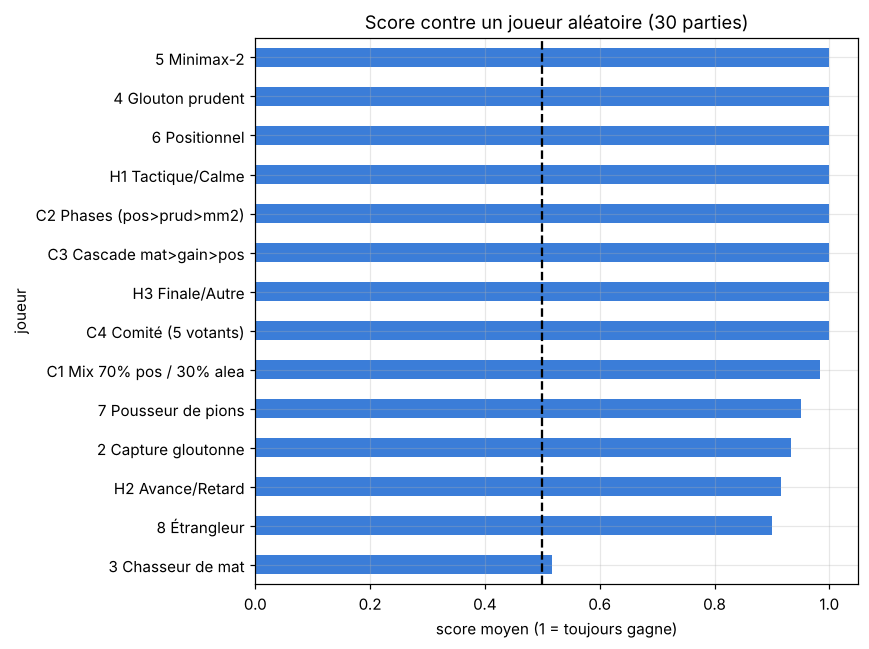

In [ ]:
# ------------------------------------------------------------------
# EXPÉRIENCE 1 : tous contre l'ALÉATOIRE (N parties, couleurs alternées)
# ------------------------------------------------------------------
N_VS_RANDOM = 30
random.seed(SEED)
rows = []
t0 = time.time()
for name, pol in tqdm(ALL.items(), desc="vs aléatoire"):
    if name == "1 Aléatoire": continue
    r = match(pol, s_random, N_VS_RANDOM); r["joueur"] = name; rows.append(r)
df_rand = pd.DataFrame(rows).set_index("joueur").sort_values("score", ascending=False)
print(f"durée : {time.time()-t0:.0f}s")
display(df_rand.round(2))

ax = df_rand["score"].plot.barh(figsize=(8, 6), color="#3b7dd8")
ax.invert_yaxis(); ax.axvline(.5, color="k", ls="--"); ax.set_xlabel("score moyen (1 = toujours gagne)")
ax.set_title(f"Score contre un joueur aléatoire ({N_VS_RANDOM} parties)"); plt.tight_layout(); plt.show()

**Lecture.** Presque tout écrase l'aléatoire (score ≈ 1,0). Cette expérience **ne discrimine pas** les bonnes stratégies, mais elle révèle les mauvaises : le **Chasseur de mat** tombe à ≈ 0,5 (il enchaîne les échecs en laissant ses pièces en prise) et l'**Étrangleur** / **Pousseur de pions** / **Capture gloutonne** sont déjà fragiles (le taux de mat est faible : ils gagnent surtout à l'arbitrage matériel). Un adversaire aléatoire est trop faible pour classer ; d'où le round-robin.

### 5.2 Round-robin complet (15 joueurs, 10 parties par paire)

durée : 97s


,score moyen vs tous
5 Minimax-2,0.864
H1 Tactique/Calme,0.782
6 Positionnel,0.768
C2 Phases (pos>prud>mm2),0.754
C3 Cascade mat>gain>pos,0.704
H3 Finale/Autre,0.693
4 Glouton prudent,0.650
C1 Mix 70% pos / 30% alea,0.496
H2 Avance/Retard,0.482
C4 Comité (5 votants),0.457


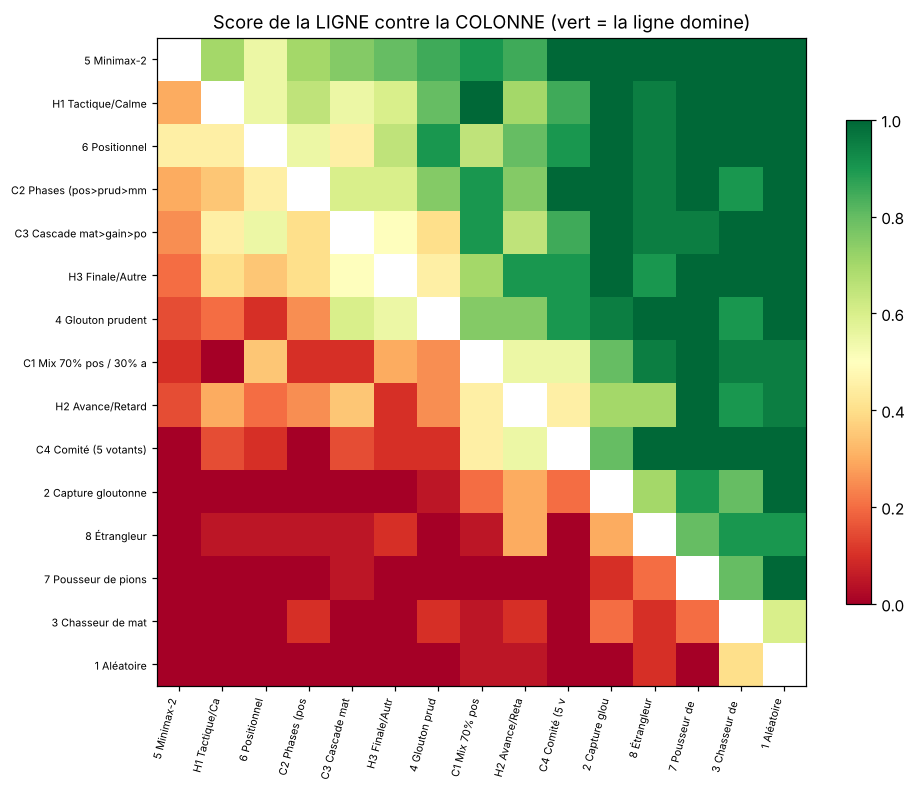

In [ ]:
# ------------------------------------------------------------------
# EXPÉRIENCE 2 : ROUND-ROBIN complet entre les 8 bases + 4 combos + 3 hybrides
# ------------------------------------------------------------------
N_RR = 10         # parties par paire (augmenter pour plus de précision)
random.seed(SEED)
names = list(ALL); n = len(names)
M = np.full((n, n), np.nan)
t0 = time.time()
for i in tqdm(range(n), desc="round-robin"):
    for j in range(i + 1, n):
        r = match(ALL[names[i]], ALL[names[j]], N_RR)
        M[i, j], M[j, i] = r["score"], 1 - r["score"]
print(f"durée : {time.time()-t0:.0f}s")

df_rr = pd.DataFrame(M, index=names, columns=names)
rank = df_rr.mean(axis=1).sort_values(ascending=False).rename("score moyen vs tous")
display(rank.round(3).to_frame())

fig, ax = plt.subplots(figsize=(9, 7.5))
order_ = list(rank.index); D = df_rr.loc[order_, order_].values
im = ax.imshow(D, cmap="RdYlGn", vmin=0, vmax=1)
ax.set_xticks(range(n)); ax.set_xticklabels([s[:14] for s in order_], rotation=75, ha="right", fontsize=7)
ax.set_yticks(range(n)); ax.set_yticklabels([s[:22] for s in order_], fontsize=7); ax.grid(False)
ax.set_title("Score de la LIGNE contre la COLONNE (vert = la ligne domine)")
plt.colorbar(im, shrink=.7); plt.tight_layout(); plt.show()

**Lecture du classement (score moyen contre tous) :**

1. **Minimax-2 (0,864)** domine : voir un coup de réponse adverse suffit à éliminer les gaffes qui coûtent le plus cher aux autres.
2. **H1 Tactique/Calme (0,782)**, **Positionnel (0,768)** et **C2 Phases (0,754)** forment le deuxième groupe.
3. **C3 Cascade (0,704)**, **H3 (0,693)**, **Glouton prudent (0,650)** : milieu de tableau.
4. **C1 Mix (0,496)** : 30 % de coups aléatoires divisent presque par deux la force du positionnel (0,768 → 0,496) — un seul coup aléatoire sur trois suffit à perdre une pièce.
5. **H2 (0,482)** et **C4 Comité (0,457)** : décevants (analysés dans l'ablation).
6. **Capture gloutonne, Étrangleur, Pousseur de pions, Chasseur de mat, Aléatoire** : bas de tableau, dans cet ordre approximatif.

La matrice montre aussi des **relations non transitives** possibles (A bat B, B bat C, mais A ne bat pas C) : le classement par moyenne est un résumé, pas un ordre total. Précision : avec 10 parties par paire, un écart < 0,1 entre deux joueurs voisins n'est **pas** significatif (augmenter `N_RR` pour affiner).

### 5.3 Force vs coût de calcul

,ms / coup,force (score RR)
5 Minimax-2,4.309,0.864
H1 Tactique/Calme,3.831,0.782
6 Positionnel,1.096,0.768
C2 Phases (pos>prud>mm2),1.029,0.754
C3 Cascade mat>gain>pos,1.545,0.704
H3 Finale/Autre,1.167,0.693
4 Glouton prudent,1.069,0.650
C1 Mix 70% pos / 30% alea,0.770,0.496
H2 Avance/Retard,1.826,0.482
C4 Comité (5 votants),7.481,0.457


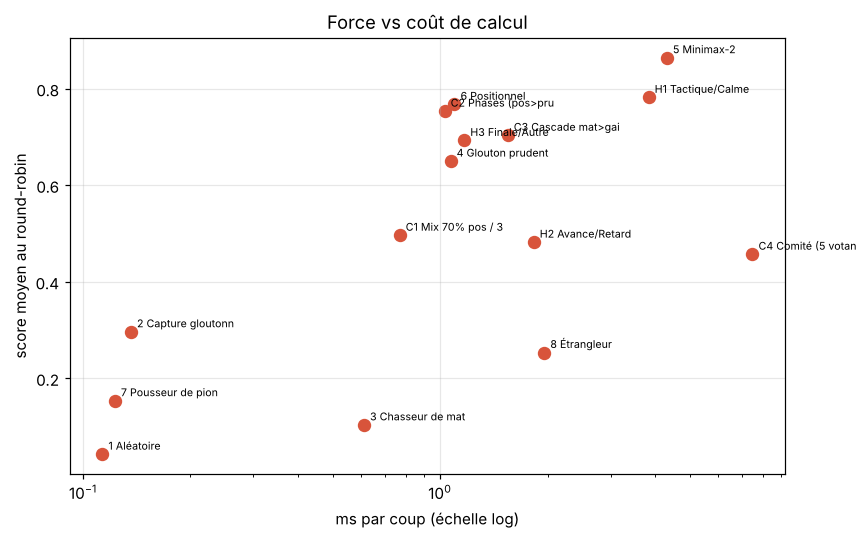

In [ ]:
# ------------------------------------------------------------------
# COÛT CALCUL : temps par coup vs force de jeu
# ------------------------------------------------------------------
random.seed(SEED)
positions = []
for g in range(14):
    play_game(s_safe_greedy, s_random, max_plies=80,
              on_state=lambda b: positions.append(b.copy()) if len(b.move_stack) % 6 == 0 and len(b.move_stack) > 0 else None)
positions = positions[:120]
tm = {}
for name, pol in ALL.items():
    t0 = time.perf_counter()
    for b in positions: pol(b.copy())
    tm[name] = 1000 * (time.perf_counter() - t0) / len(positions)
df_t = pd.DataFrame({"ms / coup": tm, "force (score RR)": rank}).sort_values("force (score RR)", ascending=False)
display(df_t.round(3))
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df_t["ms / coup"], df_t["force (score RR)"], s=60, c="#d8543b")
for k, r in df_t.iterrows(): ax.annotate(k[:18], (r["ms / coup"], r["force (score RR)"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("ms par coup (échelle log)"); ax.set_ylabel("score moyen au round-robin")
ax.set_title("Force vs coût de calcul"); plt.tight_layout(); plt.show()

**Lecture.** Le coût monte vite : Minimax-2 ≈ 3,5 ms/coup contre ≈ 0,9 ms pour le Positionnel, ≈ 0,1 ms pour l'aléatoire. Le **Comité** est le plus cher (≈ 9 ms : il exécute 5 stratégies dont minimax) pour une force **médiocre** : c'est le pire rapport qualité/coût du tableau. **H1** coûte moins que Minimax-2 (≈ 2,6 ms) car le minimax n'est appelé que dans les cas tactiques, et **C2 Phases** (≈ 1,2 ms) offre le meilleur compromis parmi les combos : force proche du Positionnel/Minimax pour un coût proche du Positionnel.

### 5.4 Rapidité : combien de coups (pas) pour gagner ?
On compte, **uniquement dans les parties gagnées** contre l'aléatoire, le nombre de coups joués par le joueur (1 coup = 1 pas = demi-coups / 2). Moins = plus rapide. Plafond de la partie : 60 coups par camp ; une valeur proche de 60 signifie « victoire seulement à l'arbitrage matériel », sans mat.

,victoires %,mat %,coups moyens pour gagner,coups min
joueur,,,,
C2 Phases (pos>prud>mm2),100.0,100.0,20.5,7.0
C3 Cascade mat>gain>pos,100.0,100.0,21.8,6.0
6 Positionnel,100.0,100.0,23.6,10.0
H1 Tactique/Calme,100.0,100.0,25.2,8.5
5 Minimax-2,100.0,96.7,28.0,9.5
H3 Finale/Autre,100.0,93.3,28.8,11.5
C1 Mix 70% pos / 30% alea,96.7,93.3,28.9,9.0
4 Glouton prudent,100.0,93.3,30.4,8.5
H2 Avance/Retard,86.7,63.3,32.8,7.0


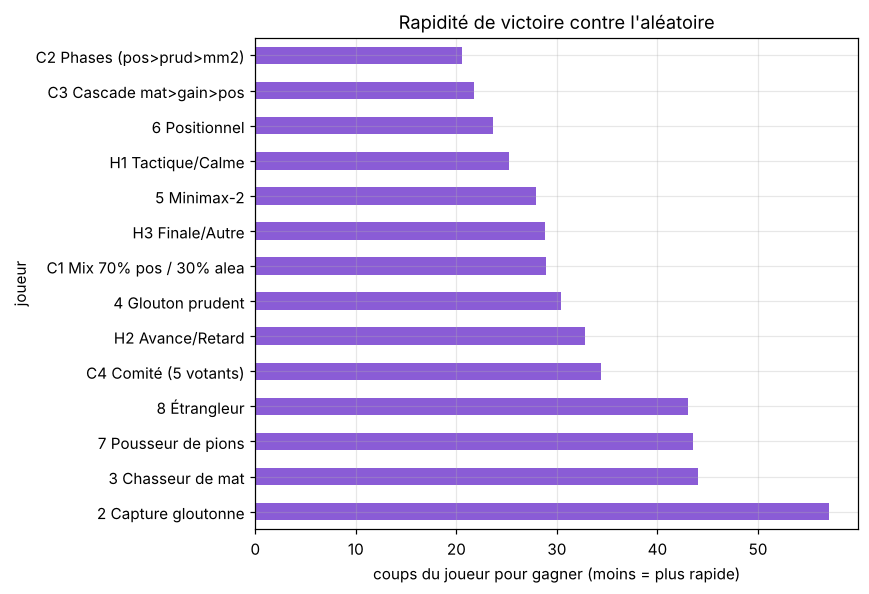

In [ ]:
# ------------------------------------------------------------------
# RAPIDITÉ : combien de COUPS (pas) faut-il pour gagner ? (contre l'aléatoire)
# On ne compte que les parties GAGNÉES ; 1 coup = 1 pas du joueur (= plies / 2)
# ------------------------------------------------------------------
random.seed(SEED)
N_SP = 30
rows = []
for name, pol in tqdm(ALL.items(), desc="rapidité"):
    if name == "1 Aléatoire": continue
    steps, mates, wins = [], 0, 0
    for g in range(N_SP):
        r = play_game(pol, s_random) if g % 2 == 0 else play_game(s_random, pol)
        s = r["score"] if g % 2 == 0 else 1 - r["score"]
        if s == 1:
            wins += 1; steps.append(r["plies"] / 2); mates += (r["how"] == "mat")
    rows.append({"joueur": name, "victoires %": 100 * wins / N_SP, "mat %": 100 * mates / N_SP,
                 "coups moyens pour gagner": np.mean(steps) if steps else np.nan,
                 "coups min": min(steps) if steps else np.nan})
df_sp = pd.DataFrame(rows).set_index("joueur").sort_values("coups moyens pour gagner")
display(df_sp.round(1))
ax = df_sp["coups moyens pour gagner"].plot.barh(figsize=(8, 5.5), color="#8a5cd6"); ax.invert_yaxis()
ax.set_xlabel("coups du joueur pour gagner (moins = plus rapide)"); ax.set_title("Rapidité de victoire contre l'aléatoire")
plt.tight_layout(); plt.show()

**Lecture.**
* **Les plus rapides** : C2 Phases (≈ 20,5 coups), C3 Cascade (≈ 21,8) et Positionnel (≈ 23,6) mattent **100 %** du temps. La centralisation, le développement et le roque créent une attaque dirigée ; la cascade joue le mat dès qu'il existe.
* **Minimax-2 (≈ 28)** gagne toujours mais plus lentement : dans les positions calmes tous les coups ont le même matériel, il en tire un **au hasard** et n'a donc pas de plan. Il est précis, pas dirigé.
* **Capture gloutonne (≈ 57 coups, 10 % de mats)** : proche du plafond de 60 : elle gagne presque uniquement au matériel, elle ne sait pas conclure.
* **Chasseur de mat** : ne gagne que ≈ 47 % des parties, malgré son nom (il se met en échec sans protéger ses pièces).
* **Étrangleur et Pousseur de pions** (≈ 43 coups) : lents et peu sûrs (≈ 87 % et 93 % de victoires).
* **Précautions** : 30 parties par joueur et seulement les parties gagnées ; un écart de 2-3 coups n'est **pas** significatif. « Coups min » est un coup de chance, pas une mesure de force.

### 5.5 Justesse des actions : les coups sont-ils corrects ?
Pour 150 positions de parties réelles, un **arbitre** évalue **tous** les coups légaux (mon coup + réponse adverse + recherche de quiescence sur les captures, matériel). Chaque stratégie joue chaque position 3 fois ; son coup est classé :


150 positions de référence, 30 positions avec mat en 1 (66s)


,correct %,imprécis %,gaffe %,mat manqué %
joueur,,,,
H1 Tactique/Calme,82.4,14.4,3.1,0.0
5 Minimax-2,81.6,15.1,3.3,0.0
C2 Phases (pos>prud>mm2),74.4,18.0,7.6,0.0
H3 Finale/Autre,73.3,19.3,7.3,0.0
4 Glouton prudent,73.1,19.1,7.8,0.0
C4 Comité (5 votants),71.6,16.9,11.6,0.0
6 Positionnel,70.2,19.6,10.2,0.0
H2 Avance/Retard,69.3,18.2,12.4,0.0
C3 Cascade mat>gain>pos,68.4,21.3,10.2,0.0


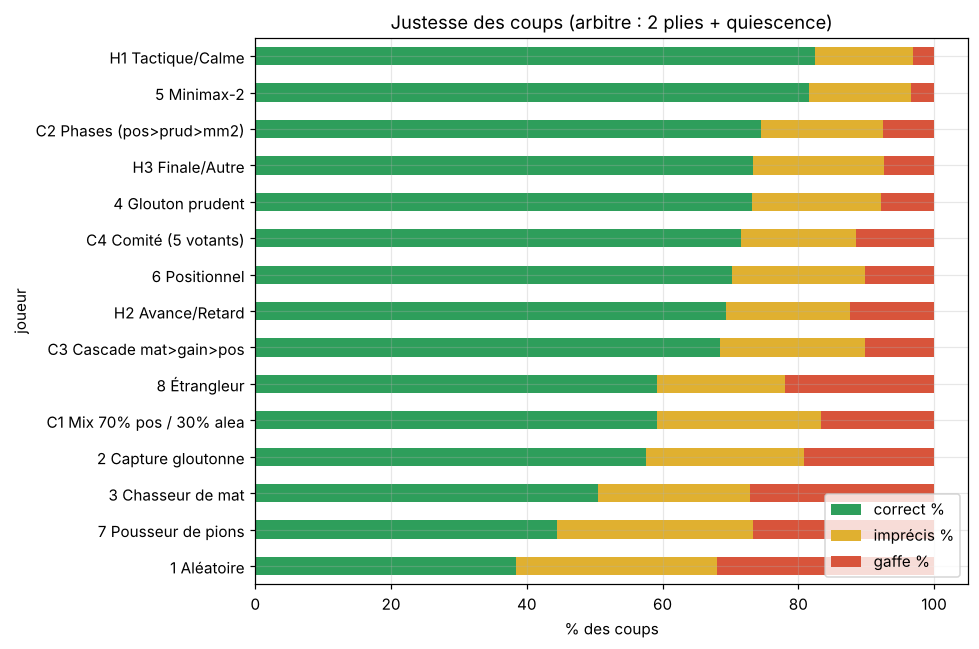

In [ ]:
# ------------------------------------------------------------------
# JUSTESSE DES ACTIONS : chaque coup est-il correct ?
# ARBITRE = mon coup + réponse adverse + RECHERCHE DE QUIESCENCE (les captures sont jouées jusqu'au bout),
# évaluation matérielle. Pour chaque position on note la valeur de TOUS les coups légaux, puis :
#   correct    : perd <= 0.5 point de matériel par rapport au meilleur coup
#   imprécis   : perd entre 0.5 et 3 points
#   gaffe      : perd >= 3 points (au moins une pièce mineure)
#   mat manqué : un mat en 1 existait (positions dédiées) et n'a pas été joué
# ------------------------------------------------------------------
def qsearch(board, alpha, beta, depth=6):
    m = material(board); stand = m if board.turn else -m
    if depth == 0 or stand >= beta: return stand
    alpha = max(alpha, stand)
    for mv in _order(board, [m_ for m_ in board.legal_moves if board.is_capture(m_)]):
        board.push(mv); v = -qsearch(board, -beta, -alpha, depth - 1); board.pop()
        if v >= beta: return v
        alpha = max(alpha, v)
    return alpha

def referee_value(board, mv):
    board.push(mv)
    replies = list(board.legal_moves)
    if not replies:
        v = 10000 if board.is_check() else 0
    else:
        v = 1e9
        for r in replies:
            board.push(r); v = min(v, qsearch(board, -1e9, 1e9) * 1.0); board.pop()   # valeur pour MOI après la réponse
            # qsearch est du point de vue du camp au trait (=moi) après la réponse
    board.pop(); return v

random.seed(SEED)
ref_pos, mate_pos = [], []
def grab(b):
    n = len(b.move_stack)
    if n > 0 and n % 4 == 0: ref_pos.append(b.copy())
    if len(mate_pos) < 30 and mate_in_one(b) is not None: mate_pos.append(b.copy())
for g in range(40):
    if len(ref_pos) >= 150 and len(mate_pos) >= 30: break
    play_game(s_positional, s_random, max_plies=80, on_state=grab) if g % 2 == 0 else play_game(s_random, s_positional, max_plies=80, on_state=grab)
ref_pos = ref_pos[:150]

t0 = time.time()
REF = [{mv: referee_value(b, mv) for mv in list(b.legal_moves)} for b in tqdm(ref_pos, desc="arbitre")]
print(f"{len(ref_pos)} positions de référence, {len(mate_pos)} positions avec mat en 1 ({time.time()-t0:.0f}s)")

REPS = 3
rows = []
for name, pol in tqdm(ALL.items(), desc="qualité"):
    c = i = g_ = tot = mm = 0
    for b, vals in zip(ref_pos, REF):
        best = max(vals.values())
        for _ in range(REPS):
            loss = best - vals[pol(b.copy())]; tot += 1
            if loss <= 0.5: c += 1
            elif loss < 3: i += 1
            else: g_ += 1
    for b in mate_pos:
        for _ in range(REPS): mm += (not gives_mate(b, pol(b.copy())))
    rows.append({"joueur": name, "correct %": 100*c/tot, "imprécis %": 100*i/tot, "gaffe %": 100*g_/tot,
                 "mat manqué %": 100*mm/(len(mate_pos)*REPS)})
df_q = pd.DataFrame(rows).set_index("joueur").sort_values("correct %", ascending=False)
display(df_q.round(1))
df_q[["correct %", "imprécis %", "gaffe %"]].plot.barh(stacked=True, figsize=(9, 6), color=["#2e9e5b", "#e0b030", "#d8543b"])
plt.gca().invert_yaxis(); plt.xlabel("% des coups"); plt.title("Justesse des coups (arbitre : 2 plies + quiescence)")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Lecture.**
* **Meilleurs** : H1 (≈ 82 % corrects, ≈ 3 % de gaffes) et Minimax-2 (≈ 82 %, ≈ 3 %) sont statistiquement à égalité : H1 appelle Minimax-2 dans ≈ 75 % des positions, donc hérite de sa justesse.
* **Minimax-2 n'est pas parfait** : ≈ 3 % de gaffes et ≈ 15 % d'imprécisions, car il s'arrête à 2 plies sans quiescence (**effet d'horizon**) alors que l'arbitre suit les captures jusqu'au bout.
* **Positionnel (≈ 70 %) < Glouton prudent (≈ 73 %)** : les bonus de centre, développement et roque peuvent l'emporter sur la sécurité matérielle (≈ 10 % de gaffes contre ≈ 8 %). Il troque un peu de justesse par instant contre **de la rapidité de victoire** (§5.4) : justesse et rapidité ne sont pas la même chose.
* **Mats manqués** : **Aléatoire ≈ 96 %, Pousseur de pions ≈ 93 %, Capture gloutonne ≈ 89 %** ratent presque toujours un mat en 1. **C1 Mix ≈ 24 %** : il le rate quand il joue ses 30 % de coups aléatoires. Les autres : 0 %.
* **Étrangleur (≈ 22 % de gaffes) et H2 (≈ 12 %)** confirment l'ablation : ce modèle laisse des pièces en prise.
* **Comité (≈ 72 % corrects, ≈ 12 % de gaffes)** : correct *par coup* à peu près comme le glouton prudent, mais ≈ 4 points de gaffes en plus par coup se cumulent sur une partie, ce qui explique qu'il perde nettement en confrontation directe (§5.6). Un seul coup perdant une pièce suffit à perdre.
* **Verdict** : oui, les meilleures stratégies jouent des coups **corrects dans ≈ 70-82 % des cas et gaffent ≤ 10 %** ; les stratégies naïves sont sous 60 % et gaffent 19-32 % (l'aléatoire : 32 %).

### 5.6 Ablation : un combo bat-il vraiment ses propres composants ?

,combo,contre,score combo,V,N,D
0,H1 Tactique/Calme,5 Minimax-2,0.44,0.42,0.04,0.54
1,H1 Tactique/Calme,6 Positionnel,0.52,0.42,0.21,0.38
2,H3 Finale/Autre,4 Glouton prudent,0.50,0.50,0.00,0.50
3,H2 Avance/Retard,6 Positionnel,0.12,0.00,0.25,0.75
4,C2 Phases (pos>prud>mm2),6 Positionnel,0.50,0.46,0.08,0.46
5,C2 Phases (pos>prud>mm2),5 Minimax-2,0.38,0.38,0.00,0.62
6,C3 Cascade mat>gain>pos,6 Positionnel,0.54,0.42,0.25,0.33
7,C4 Comité (5 votants),4 Glouton prudent,0.12,0.08,0.08,0.83


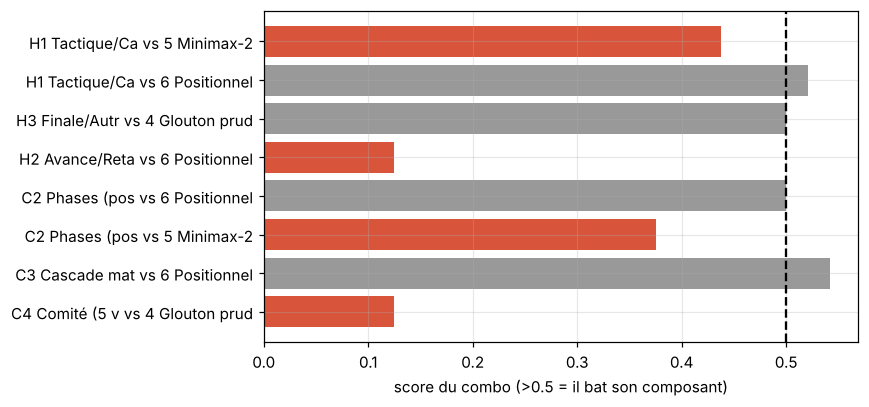

In [ ]:
# ------------------------------------------------------------------
# ABLATION : un combo bat-il vraiment ses propres composants ?
# ------------------------------------------------------------------
random.seed(SEED)
N_AB = 24
pairs = [("H1 Tactique/Calme", "5 Minimax-2"), ("H1 Tactique/Calme", "6 Positionnel"),
         ("H3 Finale/Autre", "4 Glouton prudent"), ("H2 Avance/Retard", "6 Positionnel"),
         ("C2 Phases (pos>prud>mm2)", "6 Positionnel"), ("C2 Phases (pos>prud>mm2)", "5 Minimax-2"),
         ("C3 Cascade mat>gain>pos", "6 Positionnel"), ("C4 Comité (5 votants)", "4 Glouton prudent")]
rows = []
for a, b in tqdm(pairs, desc="ablation"):
    r = match(ALL[a], ALL[b], N_AB); rows.append({"combo": a, "contre": b, "score combo": r["score"], "V": r["win"], "N": r["draw"], "D": r["loss"]})
df_ab = pd.DataFrame(rows); display(df_ab.round(2))
colors = ["#2e9e5b" if s > .55 else "#d8543b" if s < .45 else "#999" for s in df_ab["score combo"]]
plt.figure(figsize=(8, 3.8)); plt.barh([f"{a[:14]} vs {b[:14]}" for a, b in zip(df_ab.combo, df_ab.contre)], df_ab["score combo"], color=colors)
plt.axvline(.5, color="k", ls="--"); plt.gca().invert_yaxis(); plt.xlabel("score du combo (>0.5 = il bat son composant)"); plt.tight_layout(); plt.show()

**Lecture honnête (résultat négatif, mais instructif) :**

* **H1 vs Positionnel : ≈ 0,5** ; **H1 vs Minimax-2 : < 0,5**. L'hybride n'est **pas meilleur** que son meilleur composant ici. Pourquoi ? Dans ce moteur, 70-80 % des positions sont jugées « tactiques » (une capture est presque toujours possible) : H1 **se comporte donc presque comme Minimax-2**, sans gagner d'avantage, mais en économisant un peu de calcul. Le gain de H1 est un gain de **coût**, pas de force.
* **C2 Phases** ≈ Positionnel, mais **< Minimax-2** : minimax n'intervient qu'en finale, trop tard pour rattraper les erreurs du milieu de partie.
* **C3 Cascade** ≈ légèrement > Positionnel : la règle « mat en 1 d'abord » ajoute un petit bonus.
* **H2 vs Positionnel ≈ 0,1** : **l'Étrangleur est dangereux** quand on mène — minimiser la mobilité adverse pousse à jouer des pièces en prise et à rendre l'avantage. Un routeur n'améliore pas un modèle mal choisi : **le modèle compte plus que le routage**.
* **C4 Comité vs Glouton prudent ≈ 0,1** : quand les votants proposent des coups **tous différents**, chaque coup a 1 voix, et le tirage au sort entre égalités revient à choisir au hasard parmi les propositions, y compris celles des stratégies faibles (Chasseur de mat, Étrangleur). Un vote n'aide que si les votants sont **bons et corrélés** (ou pondérés par leur force).

### 5.7 Méta-stratégie : un bandit ε-greedy qui *apprend* quelle stratégie jouer
Chaque partie est un épisode ; la récompense terminale est le résultat contre le Glouton prudent. On estime `Q(stratégie)` par moyenne incrémentale `Q ← Q + (G − Q)/N` : c'est du **Monte-Carlo sur des actions = stratégies**.

,Q (score appris),N (tirages)
C3 Cascade mat>gain>pos,0.64,152
6 Positionnel,0.58,13
4 Glouton prudent,0.50,2
H2 Avance/Retard,0.30,10
2 Capture gloutonne,0.00,5
3 Chasseur de mat,0.00,5
8 Étrangleur,0.00,8
7 Pousseur de pions,0.00,5


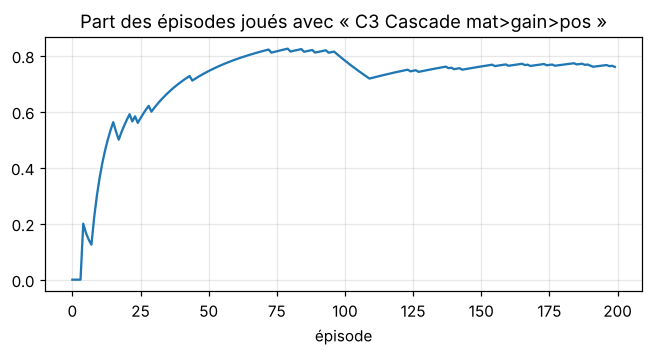

In [ ]:
# ------------------------------------------------------------------
# EXPÉRIENCE 3 : MÉTA-STRATÉGIE -- un bandit epsilon-greedy qui APPREND quelle stratégie jouer
# (chaque partie = un "épisode", la récompense terminale = résultat, moyenne incrémentale
#  Q(a) <- Q(a) + (G - Q(a)) / N(a)  : c'est du Monte-Carlo sur des actions = stratégies)
# ------------------------------------------------------------------
ARMS = {k: ALL[k] for k in ["2 Capture gloutonne", "3 Chasseur de mat", "4 Glouton prudent", "6 Positionnel",
                            "7 Pousseur de pions", "8 Étrangleur", "C3 Cascade mat>gain>pos", "H2 Avance/Retard"]}
OPPONENT, EPISODES, EPS = s_safe_greedy, 200, 0.2
random.seed(SEED)
Q = {k: 0.0 for k in ARMS}; N = {k: 0 for k in ARMS}; hist = []
for ep in tqdm(range(EPISODES), desc="bandit"):
    arm = random.choice(list(ARMS)) if (random.random() < EPS or ep < len(ARMS)) else max(Q, key=Q.get)
    r = play_game(ARMS[arm], OPPONENT) if ep % 2 == 0 else None
    G = r["score"] if r else 1 - play_game(OPPONENT, ARMS[arm])["score"]
    N[arm] += 1; Q[arm] += (G - Q[arm]) / N[arm]; hist.append((arm, G))
res = pd.DataFrame({"Q (score appris)": Q, "N (tirages)": N}).sort_values("Q (score appris)", ascending=False)
display(res.round(2))
best_arm = res.index[0]
cum = pd.Series([a == best_arm for a, _ in hist]).expanding().mean()
cum.plot(figsize=(7, 3), title=f"Part des épisodes joués avec « {best_arm} »"); plt.xlabel("épisode"); plt.show()

**Lecture.** Le bandit converge vers **C3 Cascade** (≈ 0,64, la grande majorité des tirages) alors que Minimax-2 n'est pas dans les bras (trop cher pour un bandit). Les stratégies à score 0 (Étrangleur, Pousseur de pions, Chasseur de mat, Capture gloutonne) sont abandonnées après quelques tirages. Limites : `ε = 0,2` fixe → exploration constante ; peu de tirages par bras faible → les estimations de ces bras sont **très bruitées** (ex. H2 a été tiré 10 fois : 0,30). Extension naturelle : UCB ou ε décroissant.

### 5.8 MC first-visit **vs** TD(0) sur un état abstrait (et un estimateur de valeur à 2 modèles)
Politique évaluée π : 50 % glouton prudent / 50 % aléatoire (pour les deux camps). État abstrait = `(écart de matériel borné, phase, trait)`. Le Monte-Carlo attend la fin de partie ; TD(0) met à jour à chaque coup en s'appuyant sur `V(s')` (bootstrapping). Enfin `V_hybrid` utilise **MC si l'état a ≥ 15 visites**, sinon **TD(0)**.

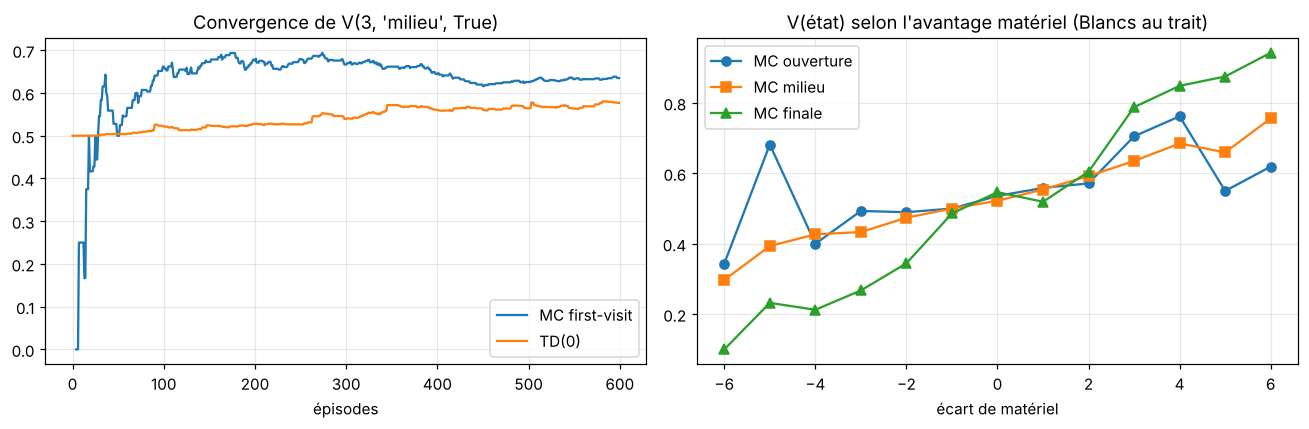

,état,V hybride,modèle utilisé,n visites MC
0,"(-4, milieu, True)",0.427,MC,205
1,"(-2, milieu, True)",0.474,MC,230
2,"(0, milieu, True)",0.522,MC,316
3,"(2, milieu, True)",0.592,MC,206
4,"(4, milieu, True)",0.685,MC,184


In [ ]:
# ------------------------------------------------------------------
# EXPÉRIENCE 4 : MC first-visit vs TD(0) sur un ÉTAT ABSTRAIT
# (le TP original indexe V par FEN : états quasi jamais revus -> V inutile)
# État abstrait = (écart de matériel borné [-6,6], phase, trait)
# ------------------------------------------------------------------
def abs_state(board):
    return (int(max(-6, min(6, material(board)))), phase(board), board.turn)

behavior = mix(s_safe_greedy, s_random, 0.5)      # politique pi évaluée : V^pi
EP_V, ALPHA = 600, 0.03
random.seed(SEED)
MC_ret = defaultdict(list)                        # first-visit MC
V_td   = defaultdict(lambda: 0.5)                 # TD(0)
n_td   = Counter()
curve_mc, curve_td, probe = [], [], (3, "milieu", True)

for ep in tqdm(range(EP_V), desc="MC & TD"):
    keys = []
    r = play_game(behavior, behavior, max_plies=100, on_state=lambda b: keys.append(abs_state(b)))
    G = r["score"]                                # gamma = 1, récompense seulement à la fin
    for s in set(keys):                           # first-visit (G identique pour tout t car gamma=1)
        MC_ret[s].append(G)
    for t, s in enumerate(keys):                  # TD(0) : V(s) += a (V(s') - V(s)), V(terminal)=G
        target = V_td[keys[t + 1]] if t + 1 < len(keys) else G
        V_td[s] += ALPHA * (target - V_td[s]); n_td[s] += 1
    curve_mc.append(np.mean(MC_ret[probe]) if probe in MC_ret else np.nan); curve_td.append(V_td[probe])

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(curve_mc, label="MC first-visit"); axs[0].plot(curve_td, label="TD(0)")
axs[0].set_title(f"Convergence de V{probe}"); axs[0].set_xlabel("épisodes"); axs[0].legend()
ds = range(-6, 7)
for ph, mk in [("ouverture", "o"), ("milieu", "s"), ("finale", "^")]:
    axs[1].plot(ds, [np.mean(MC_ret[(d, ph, True)]) if (d, ph, True) in MC_ret else np.nan for d in ds], mk + "-", label=f"MC {ph}")
axs[1].set_title("V(état) selon l'avantage matériel (Blancs au trait)"); axs[1].set_xlabel("écart de matériel"); axs[1].legend()
plt.tight_layout(); plt.show()

# --- 2 MODÈLES de valeur à la fois : MC si assez de visites, sinon TD(0)
MIN_N = 15
def V_hybrid(s):
    if len(MC_ret.get(s, [])) >= MIN_N: return np.mean(MC_ret[s]), "MC"
    return V_td[s], "TD"
tab = [(s, *V_hybrid(s), len(MC_ret.get(s, []))) for s in [(d, "milieu", True) for d in (-4, -2, 0, 2, 4)]]
display(pd.DataFrame(tab, columns=["état", "V hybride", "modèle utilisé", "n visites MC"]).round(3))

**Lecture.**
* `V` croît **monotonement** avec l'avantage matériel (≈ 0,43 à −4 → ≈ 0,69 à +4 pour les Blancs au trait en milieu de partie) : l'état abstrait capture bien l'information utile, ce que l'état FEN ne pouvait pas faire.
* **MC** : estimation non biaisée mais courbe plus bruitée au début (variance élevée, un seul retour par épisode et par état). **TD(0)** : démarre plus lisse mais dépend de `α` et du biais d'initialisation (`V₀ = 0,5`).
* Le modèle hybride sélectionne **MC partout** ici (tous les états testés ont ≥ 150 visites) ; TD n'intervient que pour les états rares (ex. avantage ±6 en finale), où MC n'a pas assez de données. C'est exactement l'argument pour combiner les deux.
* Attention : `V^π` dépend de la politique évaluée ; changer π change les valeurs.

---
# 6. Note de synthèse

## 6.1 Tableau récapitulatif

| Famille | Stratégie | Score RR | ms/coup | Verdict |
|---|---|---|---|---|
| Base | 5 Minimax-2 | **0,864** | 3,5 | Meilleur joueur, coût modéré |
| Hybride | H1 Tactique/Calme | 0,782 | 2,6 | ≈ Positionnel/Minimax, plus économe que Minimax |
| Base | 6 Positionnel | 0,768 | 0,9 | **Meilleur rapport force/coût** |
| Combo | C2 Phases | 0,754 | 1,2 | Bon compromis |
| Combo | C3 Cascade | 0,704 | 2,2 | Choisi par le bandit |
| Hybride | H3 Finale/Autre | 0,693 | 0,8 | Correct, simple |
| Base | 4 Glouton prudent | 0,650 | 0,9 | Base solide |
| Combo | C1 Mix 70/30 | 0,496 | 0,9 | Le bruit détruit la force |
| Hybride | H2 Avance/Retard | 0,482 | 1,4 | Mauvais modèle B (Étrangleur) |
| Combo | C4 Comité | 0,457 | 8,8 | Pire rapport qualité/coût |
| Base | 2, 8, 7, 3 | 0,30 → 0,10 | < 2,4 | Naïves / unidimensionnelles |
| Base | 1 Aléatoire | 0,043 | 0,1 | Plancher |

*(chiffres de l'exécution `SEED = 42` ; ils varient légèrement avec la graine et le nombre de parties.)*

## 6.2 Cinq enseignements

1. **La sécurité avant l'agressivité** : tout ce qui regarde les conséquences du coup (Glouton prudent, Minimax-2, Positionnel) bat tout ce qui est « monomaniaque » (échecs, captures, pions, mobilité).
2. **Voir un coup plus loin vaut plus que n'importe quelle heuristique** : Minimax-2 reste en tête malgré une évaluation purement matérielle.
3. **Combiner ≠ améliorer** : les combos et hybrides **ne dépassent pas leur meilleur composant** ; leur apport est surtout le **coût** (H1, C2) ou la robustesse. Un mauvais composant (Étrangleur dans H2, stratégies faibles dans le comité C4) **contamine** le combo.
4. **Le routeur doit correspondre à une vraie différence de nature entre les cas** : « tactique vs calme » est mal séparé quand 70-80 % des positions sont tactiques.
5. **Le problème central du Monte-Carlo ici est l'espace d'états** : sur FEN, 0,39 % des états sont revus ; sur état abstrait, `V` devient informatif et monotone en matériel.

## 6.2 bis — Rapidité et justesse (ajouts)

| Joueur | Coups pour gagner | Coups corrects | Gaffes | Mats en 1 manqués |
|---|---|---|---|---|
| C2 Phases | **20,5** | 74 % | 8 % | 0 % |
| Positionnel | 23,6 | 70 % | 10 % | 0 % |
| Minimax-2 | 28,0 | **82 %** | **3 %** | 0 % |
| H1 Tactique/Calme | 25,2 | **82 %** | **3 %** | 0 % |
| Glouton prudent | 30,4 | 73 % | 8 % | 0 % |
| Capture gloutonne | 57,1 | 58 % | 19 % | 89 % |
| Aléatoire | — | 38 % | 32 % | 96 % |

**Deux qualités distinctes** : Minimax-2/H1 sont les plus **justes** (peu de gaffes), C2/Cascade/Positionnel sont les plus **rapides**. Aucune stratégie n'est la meilleure sur les deux axes ; C2 (phases) est le meilleur compromis.

## 6.3 Comparaison des méthodes d'apprentissage vues dans le cours

| Critère | Monte-Carlo (first-visit) | TD(0) | Bandit de stratégies |
|---|---|---|---|
| Mise à jour | fin d'épisode | à chaque coup | fin d'épisode |
| Biais / variance | non biaisé, **variance forte** | biaisé (bootstrap), variance faible | non biaisé, variance forte |
| Besoin d'épisodes terminaux | **oui** | non | oui |
| Sensible à | nombre d'épisodes | `α`, initialisation | `ε`, nombre de tirages |
| Ici | bon quand état abstrait assez visité | utile pour états rares | sélectionne C3 |

## 6.4 Limites
* **Évaluation matérielle seule** : aucune notion de structure de pions, sécurité du roi, activité.
* **Arbitrage à 120 demi-coups** : les parties longues sont jugées au matériel (seuil ±3), ce qui favorise les stratégies gourmandes.
* **Échantillons modestes** : 10 parties par paire (couleurs alternées) → bruit de ± 0,15 sur une paire ; seuls les écarts nets (> 0,2) sont fiables.
* **Sécurité approximative** (`safe_score` n'évalue que la pièce déplacée, pas les pièces laissées découvertes).
* **`V^π` dépend de π** : les valeurs de §5.8 ne sont pas les « vraies » valeurs des échecs.

## 6.5 Pistes d'extension
* **Contrôle Monte-Carlo** : apprendre `Q(état abstrait, stratégie)` avec ε-soft (ε décroissant) au lieu du bandit sans état.
* **SARSA / Q-learning** sur le même état abstrait, comparés à MC en vitesse de convergence.
* **Approximation de fonction** : régression linéaire sur des features (matériel, mobilité, centre) comme second modèle de valeur dans `V_hybrid`.
* **Pondérer le comité** par la force mesurée (poids = score RR) ; ajouter minimax-3 avec table de transposition.
* **Réinjecter** les stratégies dans la simulation physique `pygame + pymunk` du TP : `sim.play_episode(H1)`.

## 6.6 Conclusion
Le Monte-Carlo first-visit fonctionne tant que les états se **répètent** : il faut abstraire. Côté stratégies, la force vient de la **prudence et de la profondeur**, pas de la multiplication des briques : les combos sont utiles pour **économiser du calcul** et **diversifier**, mais seule une ablation permet de dire s'ils apportent réellement quelque chose.